# Regionalize summary stats based on Olsen biomes


Set path to include RStudio packages

In [2]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

## Load Data

### Summary stats per hexagon

In [3]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [4]:
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean_group.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_summary_stats_inkl_pca_mean_group.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean_group.csv")

combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_log10.csv")


head(combined_data)



h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,27.280,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,27.200,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,27.261,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,27.287,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,27.500,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,27.537,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460


In [5]:
dim(combined_data)

[1] 19504    44

In [6]:
summary_data <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10.csv")
head(summary_data)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,-1.8038341,-1.35482967,0.9603752,0.1581176,-0.05605286,-0.6131218,0.28704004,0.47782598,-33.141024,⋯,-0.864,55.17,44.21,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3
832834fffffffff,-1.7814382,-1.29902183,0.5006442,-0.2982885,-0.16618360,-0.6990300,0.48394999,0.65921448,-37.136897,⋯,-0.970,46.71,23.30,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3
832831fffffffff,-1.9763540,-1.59160415,0.9112940,0.3624014,-0.61732579,-1.1252867,-0.06457907,0.03630553,-24.173716,⋯,-1.237,39.56,32.01,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3
832655fffffffff,-0.2605628,0.07481552,2.5676102,2.4014114,-0.61717831,-1.1149993,0.40472226,0.25530429,-448.273661,⋯,-0.276,86.05,9.42,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
832a16fffffffff,-0.8424427,-0.25877041,2.9200629,2.5958144,-0.88607992,-2.1060823,0.45917662,0.57860174,-225.556026,⋯,-0.860,56.99,61.86,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3
8329a5fffffffff,-1.7371124,-1.63955304,-0.2342676,-1.3958365,1.27144386,0.8847160,0.20159946,0.53819018,-5.950362,⋯,-0.039,73.33,979.49,0.460,0.485,0.465,0.478,-5.15,-2.72,h3_res3


### Olsen polygons

#### Preprocessing

In [7]:
library(sf) 

wwf <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos.shp")
# Remove arctic and Antarctica
#wwf <- wwf[wwf$BIOME < 98, ]


Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



Reading layer `wwf_terr_ecos' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos.shp' using driver `ESRI Shapefile'
Simple feature collection with 14458 features and 21 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -89.89197 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84


In [8]:
print(wwf) # check the structure of the shapefile

Simple feature collection with 14458 features and 21 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -89.89197 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   OBJECTID         AREA PERIMETER                                ECO_NAME
1         1    29.802942     0.219 Northern Mesoamerican Pacific mangroves
2         2    11.977824     0.193 Northern Mesoamerican Pacific mangroves
3         3 77301.372760   111.954                    Sinaloan dry forests
4         4   215.489182     1.274 Northern Mesoamerican Pacific mangroves
5         5    19.639089     0.363 Northern Mesoamerican Pacific mangroves
6         6 19867.174705    14.323                              Everglades
7         7    51.100905     0.457 Northern Mesoamerican Pacific mangroves
8         8     9.617789     0.268 Northern Mesoamerican Pacific mangroves
9         9     8.703015     0.277                    Bahamian pine mosaic
10       10   112.752419     1.041 Northe

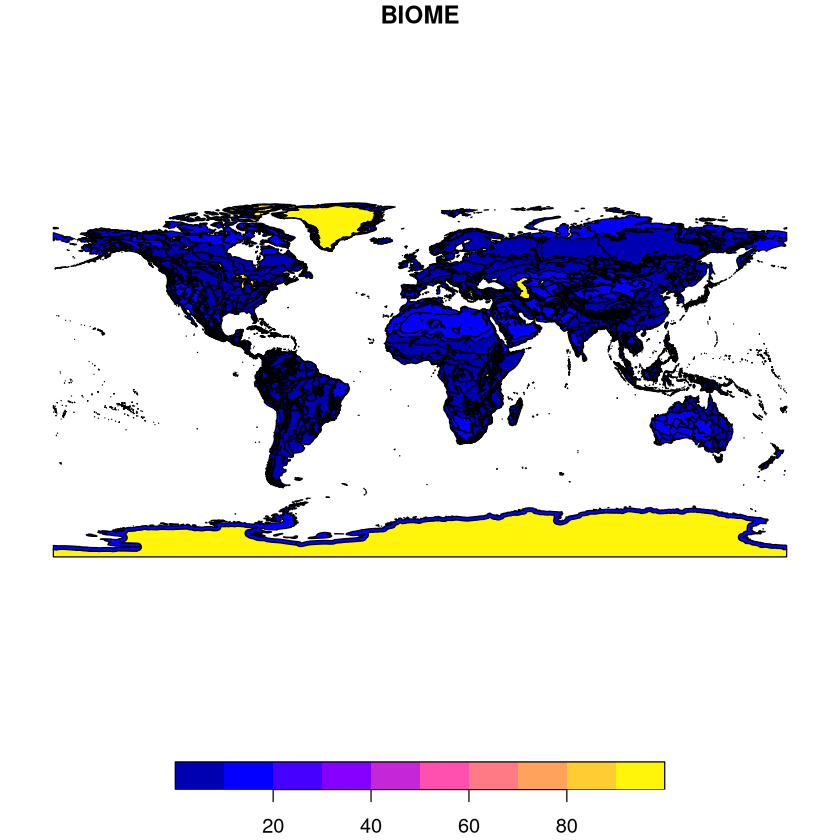

In [9]:
plot(wwf["BIOME"]) 

In [10]:
wwf$biome_realm <- paste(wwf$BIOME, wwf$REALM, sep = "_")

In [11]:
# Ensure all geometries are valid
#wwf <- st_make_valid(wwf)


In [12]:
# Aggregate polygons by BIOME and REALM
#wwf_aggregated <- wwf %>%
 #   group_by(biome_realm) %>%
  #  summarise(geometry = st_union(geometry))

# Check the structure of the aggregated data
#print(wwf_aggregated)

In [13]:
# save the aggregated shapefile
#st_write(wwf_aggregated, "~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp", delete_dsn = TRUE)

#### Load data

In [14]:
# read the aggregated shapefile
library(sf)
wwf_aggregated <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp")


Reading layer `wwf_terr_ecos_aggregated' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84


In [15]:
print(wwf_aggregated)

Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AA MULTIPOLYGON (((171.4289 -4...
2    10_AT MULTIPOLYGON (((34.56465 1....
3    10_IM MULTIPOLYGON (((116.6342 6....
4    10_NT MULTIPOLYGON (((-76.14241 4...
5    10_PA MULTIPOLYGON (((64.75403 34...
6    11_AA MULTIPOLYGON (((179.1841 -4...
7    11_AN MULTIPOLYGON (((-66.89195 -...
8    11_NA MULTIPOLYGON (((-42.17305 6...
9    11_PA MULTIPOLYGON (((149.4331 68...
10   12_AA MULTIPOLYGON (((122.7533 -3...


Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”


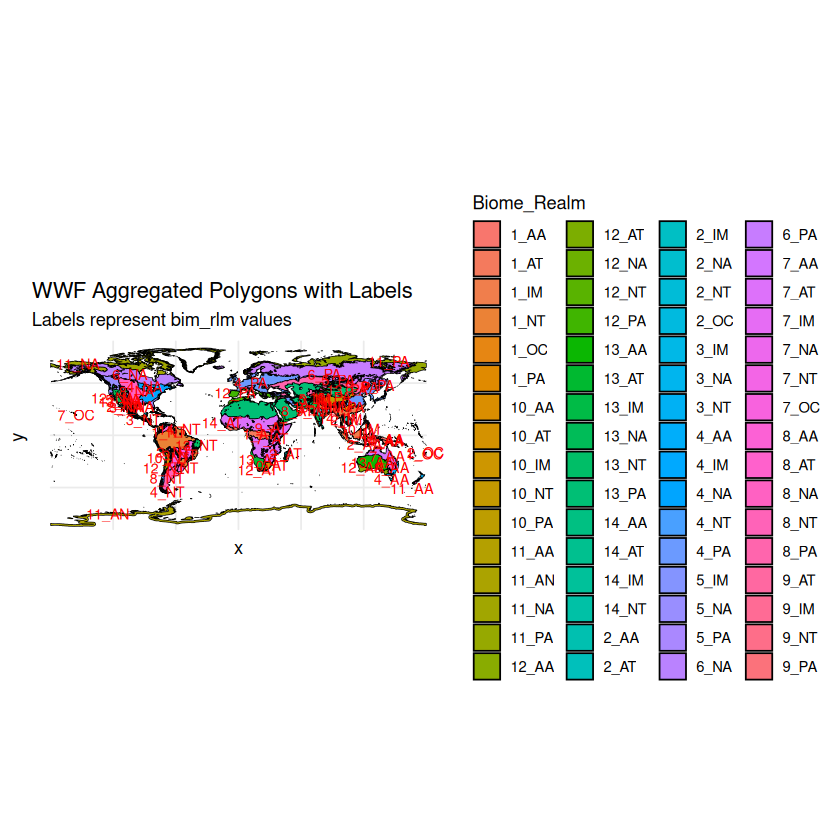

In [16]:
library(ggplot2)

# Plot the aggregated WWF data with labels and different colors for each polygon
ggplot() +
    geom_sf(data = wwf_aggregated, aes(fill = bim_rlm), color = "black") +
    geom_sf_text(data = wwf_aggregated, aes(label = bim_rlm), size = 3, color = "red") +
    theme_minimal() +
    labs(title = "WWF Aggregated Polygons with Labels",
         subtitle = "Labels represent bim_rlm values",
         fill = "Biome_Realm")

## Add BIOME and REALM code

In [17]:
# Load necessary libraries
library(sf)
library(h3)
library(dplyr)

# Step 1: Iterate over all regions in the wwf dataset
for (region in unique(wwf_aggregated$bim_rlm)) {
  # Extract the polygon for the current region
  polygon <- wwf_aggregated[wwf_aggregated$bim_rlm == region, ]
  
  # Convert the polygon to H3 cells (Resolution 3)
  region_cells <- h3::polyfill(polygon, res = 3)
  
  # Assign the region name to the corresponding cells in combined_data
  combined_data$region[combined_data$h3_res3 %in% region_cells] <- region

}


# Step 2: View the updated combined_data
head(combined_data)





Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


polygon has holes

polygon has holes



polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has 

h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471,12_NA
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478,5_NA
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,NA
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460,NA


In [18]:
# save combined_data with region info
fwrite(combined_data, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10.csv")

In [19]:
wwf_aggregated_h3 <- wwf_aggregated %>%
  rowwise() %>%
  mutate(
    h3_indexes = {
      pf <- h3::polyfill(geometry, res = 3)
      if (length(pf) == 0) { # small polygons where the no h3_hexagon centroid fall within the polygon
        # Fallback: use centroid
        centroid <- sf::st_centroid(geometry)
        coords <- sf::st_coordinates(centroid)
        pf <- h3::geo_to_h3(matrix(coords[c(2,1)], nrow=1), res = 3)  # lat, lon order
      }
      list(pf)
    },
    
    # Expand one ring as before
    h3_indexes_k1 = list({
      base <- h3_indexes
      expanded <- unique(unlist(lapply(base, function(ix) h3::k_ring(ix))))
      expanded
    }),
    
    h3_outer_ring = list(setdiff(h3_indexes_k1, h3_indexes))
  ) %>%
  ungroup()

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has 

In [20]:
print(wwf_aggregated_h3)

Simple feature collection with 64 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
# A tibble: 64 × 5
   bim_rlm                       geometry h3_indexes h3_indexes_k1 h3_outer_ring
   <chr>               <MULTIPOLYGON [°]> <list>     <list>        <list>       
 1 10_AA   (((171.4289 -43.18564, 171.42… <chr [7]>  <chr [44]>    <chr [37]>   
 2 10_AT   (((34.56465 1.082489, 34.5001… <chr [64]> <chr [175]>   <chr [111]>  
 3 10_IM   (((116.6342 6.288008, 116.646… <chr [1]>  <chr [7]>     <chr [6]>    
 4 10_NT   (((-76.14241 4.993758, -76.12… <chr [66]> <chr [148]>   <chr [82]>   
 5 10_PA   (((64.75403 34.78774, 64.7537… <chr>      <chr [519]>   <chr [257]>  
 6 11_AA   (((179.1841 -47.72759, 179.17… <chr [1]>  <chr [7]>     <chr [6]>    
 7 11_AN   (((-66.89195 -67.89795, -66.9… <chr>      <chr [589]>   <chr [348]>  
 8 11_NA   (((-42.17305 62.48101, -42.18… <chr>      <chr [73

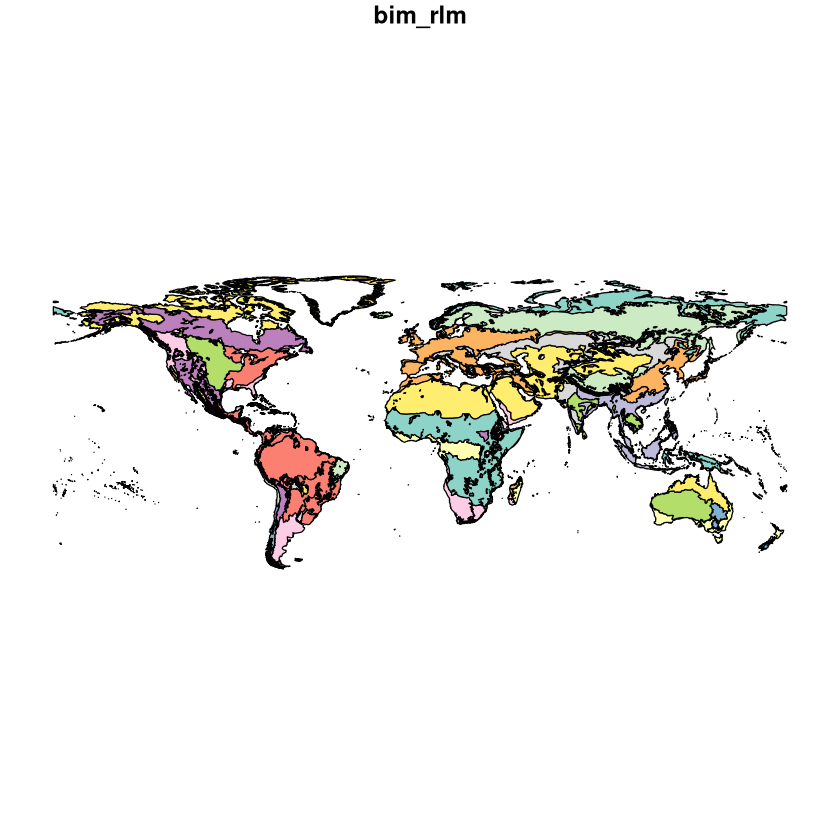

In [21]:
# Filter wwf_aggregated for bim_rlm values in unique(combined_data$region)
filtered_wwf_aggregated <- wwf_aggregated %>%
    filter(bim_rlm %in% unique(combined_data$region))

# Plot the filtered data
plot(filtered_wwf_aggregated["bim_rlm"])

## Percentage change PC1 and PC2 per region


### Choosing the Best Effect Size Metric

When comparing plant trait shifts across regions, the choice of effect size metric depends on the type of data and the research question:

- **Cohen's d**: Suitable for comparing the magnitude of differences between two groups when data is normally distributed.
- **Rank-Biserial Correlation**: Ideal for non-parametric tests like the Wilcoxon signed-rank test, as it measures the proportion of favorable differences.
- **Cliff's Delta**: Useful for ordinal data or when assessing the degree of overlap between two distributions.
- **r (Correlation Coefficient)**: Provides a standardized measure of effect size, calculated as \( r = \frac{Z}{\sqrt{N}} \), where \( Z \) is the test statistic and \( N \) is the sample size.

For plant trait shifts, **Rank-Biserial Correlation** or **Cliff's Delta** are often preferred due to their robustness to non-normal data and ability to handle ordinal or skewed distributions.

In [22]:
# Perform Kolmogorov-Smirnov test for each region and PC1, PC2, and PC3
ks_results <- combined_data %>%
    group_by(region) %>%
    summarise(
        ks_p_value_PC1 = round(ks.test(PC1[group == "all"], PC1[group == "native"])$p.value, 3),
        ks_p_value_PC2 = round(ks.test(PC2[group == "all"], PC2[group == "native"])$p.value, 3),
        ks_p_value_PC3 = round(ks.test(PC3[group == "all"], PC3[group == "native"])$p.value, 3)
    )

Warning message:
“There were 69 warnings in `summarise()`.
The first warning was:
ℹ In argument: `ks_p_value_PC1 = round(...)`.
ℹ In group 5: `region = "10_PA"`.
Caused by warning in `ks.test.default()`:
! p-value will be approximate in the presence of ties
ℹ Run `dplyr::last_dplyr_warnings()` to see the 68 remaining warnings.”


In [23]:
# Apply multiple testing correction (e.g., Benjamini-Hochberg method)
ks_results <- ks_results %>%
    mutate(
        adjusted_p_value_PC1 = p.adjust(ks_p_value_PC1, method = "BH"),
        adjusted_p_value_PC2 = p.adjust(ks_p_value_PC2, method = "BH"),
        adjusted_p_value_PC3 = p.adjust(ks_p_value_PC3, method = "BH")
    )

# Filter for adjusted p-values < 0.05
ks_results %>%
    filter(ks_p_value_PC1 < 0.05 | ks_p_value_PC2 < 0.05 | ks_p_value_PC3 < 0.05)

ks_significant <- ks_results %>%
    filter(adjusted_p_value_PC1 < 0.05 | adjusted_p_value_PC2 < 0.05 | adjusted_p_value_PC3 < 0.05) %>%
    mutate(
        significance_PC1 = case_when(
            adjusted_p_value_PC1 < 0.001 ~ "***",
            adjusted_p_value_PC1 < 0.01 ~ "**",
            adjusted_p_value_PC1 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC2 = case_when(
            adjusted_p_value_PC2 < 0.001 ~ "***",
            adjusted_p_value_PC2 < 0.01 ~ "**",
            adjusted_p_value_PC2 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC3 = case_when(
            adjusted_p_value_PC3 < 0.001 ~ "***",
            adjusted_p_value_PC3 < 0.01 ~ "**",
            adjusted_p_value_PC3 < 0.05 ~ "*",
            TRUE ~ ""
        )
    )

ks_significant

region,ks_p_value_PC1,ks_p_value_PC2,ks_p_value_PC3,adjusted_p_value_PC1,adjusted_p_value_PC2,adjusted_p_value_PC3
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10_AT,0.665,0.028,0.000,1.0000000,0.102117647,0.00000000
10_PA,0.903,0.030,0.071,1.0000000,0.103333333,0.20961905
12_AA,0.612,0.003,0.751,1.0000000,0.015500000,1.00000000
12_NA,0.479,0.004,0.075,1.0000000,0.019076923,0.21136364
12_NT,0.343,0.019,0.921,1.0000000,0.078533333,1.00000000
12_PA,0.000,0.400,0.573,0.0000000,0.729411765,0.89125000
13_IM,0.374,0.000,0.281,1.0000000,0.000000000,0.56200000
13_NA,0.788,0.066,0.010,1.0000000,0.186000000,0.04428571
13_NT,0.937,0.044,0.002,1.0000000,0.129904762,0.01240000


region,ks_p_value_PC1,ks_p_value_PC2,ks_p_value_PC3,adjusted_p_value_PC1,adjusted_p_value_PC2,adjusted_p_value_PC3,significance_PC1,significance_PC2,significance_PC3
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
10_AT,0.665,0.028,0.000,1.0000000,0.102117647,0.00000000,,,***
12_AA,0.612,0.003,0.751,1.0000000,0.015500000,1.00000000,,*,
12_NA,0.479,0.004,0.075,1.0000000,0.019076923,0.21136364,,*,
12_PA,0.000,0.400,0.573,0.0000000,0.729411765,0.89125000,***,,
13_IM,0.374,0.000,0.281,1.0000000,0.000000000,0.56200000,,***,
13_NA,0.788,0.066,0.010,1.0000000,0.186000000,0.04428571,,,*
13_NT,0.937,0.044,0.002,1.0000000,0.129904762,0.01240000,,,*
13_PA,0.143,0.034,0.003,0.8060000,0.108500000,0.01690909,,,*
1_IM,0.000,0.002,0.000,0.0000000,0.012400000,0.00000000,***,*,***


In [24]:
print(ks_significant$region) 

 [1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "13_PA" "1_IM" 
[10] "1_NT"  "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA" 
[19] "7_AA"  "7_AT"  "8_NA"  "8_NT"  NA     


In [25]:
unpaired_wilcoxon_results_global <- combined_data %>%
    summarise(
        wilcox_p_value_PC1 = wilcox.test(PC1[group == "all"], PC1[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC2 = wilcox.test(PC2[group == "all"], PC2[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC3 = wilcox.test(PC3[group == "all"], PC3[group == "native"], paired = FALSE)$p.value
    )

In [26]:
unpaired_wilcoxon_results_global

wilcox_p_value_PC1,wilcox_p_value_PC2,wilcox_p_value_PC3
<dbl>,<dbl>,<dbl>
0.8756579,5.699107e-17,3.240302e-27


In [27]:
unpaired_wilcoxon_results <- combined_data %>%
    group_by(region) %>%
    summarise(
        wilcox_p_value_PC1 = wilcox.test(PC1[group == "all"], PC1[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC2 = wilcox.test(PC2[group == "all"], PC2[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC3 = wilcox.test(PC3[group == "all"], PC3[group == "native"], paired = FALSE)$p.value
    )

Warning message:
“There were 30 warnings in `summarise()`.
The first warning was:
ℹ In argument: `wilcox_p_value_PC1 = wilcox.test(PC1[group == "all"], PC1[group
  == "native"], paired = FALSE)$p.value`.
ℹ In group 20: `region = "14_AT"`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with ties
ℹ Run `dplyr::last_dplyr_warnings()` to see the 29 remaining warnings.”


In [28]:
unpaired_wilcoxon_results <- unpaired_wilcoxon_results %>%
    mutate(
        adjusted_p_value_PC1 = p.adjust(wilcox_p_value_PC1, method = "BH"),
        adjusted_p_value_PC2 = p.adjust(wilcox_p_value_PC2, method = "BH"),
        adjusted_p_value_PC3 = p.adjust(wilcox_p_value_PC3, method = "BH")
    )

In [29]:
# Filter for adjusted p-values < 0.05
unpaired_wilcoxon_results %>%
    filter(wilcox_p_value_PC1 < 0.05 | wilcox_p_value_PC2 < 0.05 | wilcox_p_value_PC3 < 0.05)

unpaired_wilcox_significant <- unpaired_wilcoxon_results %>%
    filter(adjusted_p_value_PC1 < 0.05 | adjusted_p_value_PC2 < 0.05 | adjusted_p_value_PC3 < 0.05) %>%
    mutate(
        significance_PC1 = case_when(
            adjusted_p_value_PC1 < 0.001 ~ "***",
            adjusted_p_value_PC1 < 0.01 ~ "**",
            adjusted_p_value_PC1 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC2 = case_when(
            adjusted_p_value_PC2 < 0.001 ~ "***",
            adjusted_p_value_PC2 < 0.01 ~ "**",
            adjusted_p_value_PC2 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC3 = case_when(
            adjusted_p_value_PC3 < 0.001 ~ "***",
            adjusted_p_value_PC3 < 0.01 ~ "**",
            adjusted_p_value_PC3 < 0.05 ~ "*",
            TRUE ~ ""
        )
    )

unpaired_wilcox_significant

region,wilcox_p_value_PC1,wilcox_p_value_PC2,wilcox_p_value_PC3,adjusted_p_value_PC1,adjusted_p_value_PC2,adjusted_p_value_PC3
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10_AT,4.159083e-01,1.343170e-02,3.872802e-05,9.917813e-01,0.0489861956,4.001895e-04
10_NT,2.920654e-01,4.449978e-02,4.165689e-01,9.917813e-01,0.1199559176,6.006342e-01
12_AA,3.803348e-01,5.474439e-03,4.370071e-01,9.917813e-01,0.0268807309,6.157827e-01
12_NA,1.164081e-01,1.283752e-02,6.516858e-02,6.561184e-01,0.0489861956,1.954703e-01
12_NT,1.370685e-01,1.855402e-02,6.026850e-01,7.081872e-01,0.0622319132,7.921139e-01
12_PA,1.956123e-07,1.972643e-01,4.610393e-01,9.137679e-06,0.4133333333,6.352096e-01
13_AA,7.529582e-01,3.235447e-02,9.510304e-01,1.000000e+00,0.0911807698,1.000000e+00
13_IM,9.706848e-01,5.268967e-04,1.140552e-01,1.000000e+00,0.0042707940,2.493958e-01
13_NA,2.876995e-01,1.128255e-02,3.036256e-02,9.917813e-01,0.0466345313,1.045821e-01


region,wilcox_p_value_PC1,wilcox_p_value_PC2,wilcox_p_value_PC3,adjusted_p_value_PC1,adjusted_p_value_PC2,adjusted_p_value_PC3,significance_PC1,significance_PC2,significance_PC3
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
10_AT,4.159083e-01,1.343170e-02,3.872802e-05,9.917813e-01,0.0489861956,4.001895e-04,,*,***
12_AA,3.803348e-01,5.474439e-03,4.370071e-01,9.917813e-01,0.0268807309,6.157827e-01,,*,
12_NA,1.164081e-01,1.283752e-02,6.516858e-02,6.561184e-01,0.0489861956,1.954703e-01,,*,
12_PA,1.956123e-07,1.972643e-01,4.610393e-01,9.137679e-06,0.4133333333,6.352096e-01,***,,
13_IM,9.706848e-01,5.268967e-04,1.140552e-01,1.000000e+00,0.0042707940,2.493958e-01,,**,
13_NA,2.876995e-01,1.128255e-02,3.036256e-02,9.917813e-01,0.0466345313,1.045821e-01,,*,
13_NT,7.037827e-01,2.007481e-02,7.154133e-03,1.000000e+00,0.0622319132,3.168259e-02,,,*
1_IM,2.947638e-07,1.432780e-03,6.667583e-08,9.137679e-06,0.0088832375,1.033475e-06,***,**,***
1_NT,5.990119e-01,1.100976e-04,1.277503e-04,1.000000e+00,0.0013652107,1.131502e-03,,**,**


In [30]:
print(unpaired_wilcox_significant$region)

 [1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA"  "7_AA" 
[19] "7_AT"  "7_NT"  "8_NA"  "8_NT"  NA     


## Filter for regions with significant shifts



In [31]:
unpaired_wilcox_significant$region

[1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA"  "7_AA" 
[19] "7_AT"  "7_NT"  "8_NA"  "8_NT"  NA

In [32]:
ks_significant$region

[1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "13_PA" "1_IM" 
[10] "1_NT"  "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA" 
[19] "7_AA"  "7_AT"  "8_NA"  "8_NT"  NA

In [33]:
# filter combined_data regions in unpaired_wilcox_significant
##### or later: all regions that are either significant with citizen science or GBIF data
significant_regions <- intersect(ks_significant$region, unpaired_wilcox_significant$region)
significant_regions

[1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA"  "7_AA" 
[19] "7_AT"  "8_NA"  "8_NT"  NA

In [34]:
# merge ks_significant and unpaired_wilcox_significant
combined_significant <- merge(ks_significant, unpaired_wilcox_significant, by = "region", suffixes = c("_ks", "_wilcox"), all = TRUE)
combined_significant

region,ks_p_value_PC1,ks_p_value_PC2,ks_p_value_PC3,adjusted_p_value_PC1_ks,adjusted_p_value_PC2_ks,adjusted_p_value_PC3_ks,significance_PC1_ks,significance_PC2_ks,significance_PC3_ks,wilcox_p_value_PC1,wilcox_p_value_PC2,wilcox_p_value_PC3,adjusted_p_value_PC1_wilcox,adjusted_p_value_PC2_wilcox,adjusted_p_value_PC3_wilcox,significance_PC1_wilcox,significance_PC2_wilcox,significance_PC3_wilcox
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
1_IM,0.000,0.002,0.000,0.0000000,0.012400000,0.00000000,***,*,***,2.947638e-07,1.432780e-03,6.667583e-08,9.137679e-06,0.0088832375,1.033475e-06,***,**,***
1_NT,0.795,0.000,0.000,1.0000000,0.000000000,0.00000000,,***,***,5.990119e-01,1.100976e-04,1.277503e-04,1.000000e+00,0.0013652107,1.131502e-03,,**,**
10_AT,0.665,0.028,0.000,1.0000000,0.102117647,0.00000000,,,***,4.159083e-01,1.343170e-02,3.872802e-05,9.917813e-01,0.0489861956,4.001895e-04,,*,***
12_AA,0.612,0.003,0.751,1.0000000,0.015500000,1.00000000,,*,,3.803348e-01,5.474439e-03,4.370071e-01,9.917813e-01,0.0268807309,6.157827e-01,,*,
12_NA,0.479,0.004,0.075,1.0000000,0.019076923,0.21136364,,*,,1.164081e-01,1.283752e-02,6.516858e-02,6.561184e-01,0.0489861956,1.954703e-01,,*,
12_PA,0.000,0.400,0.573,0.0000000,0.729411765,0.89125000,***,,,1.956123e-07,1.972643e-01,4.610393e-01,9.137679e-06,0.4133333333,6.352096e-01,***,,
13_IM,0.374,0.000,0.281,1.0000000,0.000000000,0.56200000,,***,,9.706848e-01,5.268967e-04,1.140552e-01,1.000000e+00,0.0042707940,2.493958e-01,,**,
13_NA,0.788,0.066,0.010,1.0000000,0.186000000,0.04428571,,,*,2.876995e-01,1.128255e-02,3.036256e-02,9.917813e-01,0.0466345313,1.045821e-01,,*,
13_NT,0.937,0.044,0.002,1.0000000,0.129904762,0.01240000,,,*,7.037827e-01,2.007481e-02,7.154133e-03,1.000000e+00,0.0622319132,3.168259e-02,,,*


In [35]:
# regions unique to ks_significant
unique_ks_regions <- setdiff(ks_significant$region, unpaired_wilcox_significant$region)
unique_ks_regions

[1] "13_PA"

In [36]:
# regions unique to unpaired_wilcox_significant
unique_wilcox_regions <- setdiff(unpaired_wilcox_significant$region, ks_significant$region)
unique_wilcox_regions

[1] "7_NT"

In [37]:

combined_data_filtered <- combined_data %>%
    filter(region %in% unpaired_wilcox_significant$region)
    #filter(region %in% unique(c("12_AA", "13_IM", "13_NA", "2_IM",  "4_AA",  "4_NA",  "5_NA", 
     #"7_AA",  "8_NA", "12_AA" ,"13_IM", "2_IM",  "4_AA",  "4_NA",  "5_NA" , "7_AA" , "8_NA" , "8_NT" )))
head(combined_data_filtered)

significant_regions

h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471,12_NA
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478,5_NA
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,NA
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460,NA


[1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA"  "7_AA" 
[19] "7_AT"  "8_NA"  "8_NT"  NA

In [38]:
#unique(ks_significant$region)
#unique(unpaired_wilcox_significant$region)

# are there any regions that are significant in both tests?
significant_regions <- intersect(ks_significant$region, unpaired_wilcox_significant$region)

# Identify and print regions that are unique to ks_significant$region 
# but not in unpaired_wilcox_significant$region
print(setdiff(ks_significant$region, unpaired_wilcox_significant$region))

# which are regions unique in unpaired_wilcox_significant$region but 
# not in ks_significant$region?
print(setdiff(unpaired_wilcox_significant$region, ks_significant$region))


[1] "13_PA"
[1] "7_NT"


In [39]:
print(filtered_wwf_aggregated)

Simple feature collection with 61 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -55.97751 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AA MULTIPOLYGON (((171.4289 -4...
2    10_AT MULTIPOLYGON (((34.56465 1....
3    10_IM MULTIPOLYGON (((116.6342 6....
4    10_NT MULTIPOLYGON (((-76.14241 4...
5    10_PA MULTIPOLYGON (((64.75403 34...
6    11_NA MULTIPOLYGON (((-42.17305 6...
7    11_PA MULTIPOLYGON (((149.4331 68...
8    12_AA MULTIPOLYGON (((122.7533 -3...
9    12_AT MULTIPOLYGON (((22.58883 -3...
10   12_NA MULTIPOLYGON (((-118.3031 2...


### Rank-Biserial Correlation

In [40]:
rank_biserial <- function(data, value_col, group_col = "group", group1 = "all", group2 = "native") {
  # Extract values
  x <- data[[value_col]][data[[group_col]] == group1]
  y <- data[[value_col]][data[[group_col]] == group2]
  
  # Combine and rank
  combined <- c(x, y)
  ranks <- rank(combined)
  
  n1 <- length(x)
  n2 <- length(y)
  
  # Sum of ranks for x ("all"), which comes first in combined
  R1 <- sum(ranks[1:n1])
  
  # U statistic for x
  U1 <- R1 - (n1 * (n1 + 1)) / 2
  
  # Rank biserial correlation
  rbc <- (2 * U1) / (n1 * n2) - 1
  
  return(rbc)
}


In [41]:
# Initialize an empty list to store results
rbc_results <- list()

# Loop over all unique regions in combined_data_filtered
for (region in unique(combined_data_filtered$region)) {
    # Filter data for the current region
    region_data <- combined_data_filtered %>%
        filter(region == !!region)  # Use !! to correctly evaluate the variable
    
    # Calculate Rank-Biserial Correlation for PC1
    rbc_pc1 <- rank_biserial(region_data, value_col = "PC1")
    
    # Calculate Rank-Biserial Correlation for PC2
    rbc_pc2 <- rank_biserial(region_data, value_col = "PC2")
    
    # Calculate Rank-Biserial Correlation for PC3
    rbc_pc3 <- rank_biserial(region_data, value_col = "PC3")
    
    # Store the results
    rbc_results[[region]] <- data.frame(
        region = region,
        rbc_pc1 = rbc_pc1,
        rbc_pc2 = rbc_pc2,
        rbc_pc3 = rbc_pc3
    )
}

# Combine all results into a single data frame
rbc_results_df <- bind_rows(rbc_results)

# Print the results
rbc_results_df

region,rbc_pc1,rbc_pc2,rbc_pc3
<chr>,<dbl>,<dbl>,<dbl>
12_NA,-0.404958678,0.61983471,0.47107438
5_NA,-0.044321330,0.20493075,0.32337950
NA,NA,NA,NA
8_NA,-0.109312856,0.21760989,0.33606515
4_NA,-0.195966221,0.10697445,0.43889318
7_AT,0.007934007,0.10333234,0.11485434
1_NT,-0.018750113,0.13787574,0.13657687
6_NA,-0.009476195,0.04637890,0.13432234
13_NA,-0.066909422,0.15941319,0.13623473


### Cliff's Delta

Note: Rank-Biserial-Correlation was giving me exatly the same numbers. I decided to drop it

In [42]:
library(dplyr)
library(effsize) # For Cliff's Delta

# Initialize an empty list to store results
cliffs_delta_results <- list()

# Loop over all unique regions in combined_data_filtered
for (current_region in unique(combined_data_filtered$region)) {
    # Filter data for the current region
    filtered_data <- combined_data_filtered %>%
        filter(region == current_region & !is.na(PC1) & !is.na(PC2) & !is.na(PC3) & group %in% c("all", "native"))
    
    # Skip if there is insufficient data for the test
    if (nrow(filtered_data) < 2) {
        next
    }
    
    # Calculate Cliff's Delta for PC1
    cliffs_delta_PC1 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC1[filtered_data$group == "all"],
                filtered_data$PC1[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )
    
    # Calculate Cliff's Delta for PC2
    cliffs_delta_PC2 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC2[filtered_data$group == "all"],
                filtered_data$PC2[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )
    
    # Calculate Cliff's Delta for PC3
    cliffs_delta_PC3 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC3[filtered_data$group == "all"],
                filtered_data$PC3[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )
    
    # Store the results for the current region
    cliffs_delta_results[[current_region]] <- data.frame(
        region = current_region,
        cliffs_delta_PC1 = cliffs_delta_PC1,
        cliffs_delta_PC2 = cliffs_delta_PC2,
        cliffs_delta_PC3 = cliffs_delta_PC3
    )
}

# Combine all results into a single data frame
cliffs_delta_results_df <- bind_rows(cliffs_delta_results)

cliffs_delta_results_df


region,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3
<chr>,<dbl>,<dbl>,<dbl>
12_NA,-0.404958678,0.61983471,0.47107438
5_NA,-0.044321330,0.20493075,0.32337950
8_NA,-0.109312856,0.21760989,0.33606515
4_NA,-0.195966221,0.10697445,0.43889318
7_AT,0.007934007,0.10333234,0.11485434
1_NT,-0.018750113,0.13787574,0.13657687
6_NA,-0.009476195,0.04637890,0.13432234
13_NA,-0.066909422,0.15941319,0.13623473
4_AA,-0.100045269,0.47849706,0.32910819


In [43]:
# percentage change in PC1 and PC2 from region_average_native to region_average_all
pc <- combined_data_filtered %>%
    group_by(region) %>%
    summarise(
        mean_perc_change_PC1 = (mean(PC1[group == "all"]) - mean(PC1[group == "native"])) / abs(mean(PC1[group == "native"])) * 100,
        median_perc_change_PC1 = (median(PC1[group == "all"]) - median(PC1[group == "native"])) / abs(median(PC1[group == "native"])) * 100,
        mean_perc_change_PC2 = (mean(PC2[group == "all"]) - mean(PC2[group == "native"])) / abs(mean(PC2[group == "native"])) * 100,
        median_perc_change_PC2 = (median(PC2[group == "all"]) - median(PC2[group == "native"])) / abs(median(PC2[group == "native"])) * 100

    )   

pc

region,mean_perc_change_PC1,median_perc_change_PC1,mean_perc_change_PC2,median_perc_change_PC2
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
10_AT,25.1242622,29.9521348,89.409950,103.448767
12_AA,-45.1279883,-25.3650246,10.772227,11.459533
12_NA,-28.2237980,-12.5524006,76.154348,58.574562
12_PA,36.5146702,39.6651678,53.877318,66.534510
13_IM,2.9381874,-3.1917696,183.199789,631.866244
13_NA,-14.5476947,-20.4248286,19.944665,18.509465
13_NT,5.7347359,10.9591217,309.302035,519.823060
1_IM,-21.2883720,-24.6663728,17.788739,23.500696
1_NT,-2.8778945,-4.1650131,25.992187,32.317979


Common benchmarks for interpreting Cliff’s delta magnitude are:

Corresponding Cliff’s delta interpretations:
Small: |δ| ≥ 0.11
Medium: |δ| ≥ 0.28
Large: |δ| ≥ 0.43


In [44]:
# add effect size categories to cliffs_delta_results_df
cliffs_delta_results_df <- cliffs_delta_results_df %>%
    mutate(
        effect_size_PC1 = case_when(
            abs(cliffs_delta_PC1) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC1) >= 0.11 & abs(cliffs_delta_PC1) < 0.28 ~ "small",
            abs(cliffs_delta_PC1) >= 0.28 & abs(cliffs_delta_PC1) < 0.43 ~ "medium",
            abs(cliffs_delta_PC1) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        ),
        effect_size_PC2 = case_when(
            abs(cliffs_delta_PC2) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC2) >= 0.11 & abs(cliffs_delta_PC2) < 0.28 ~ "small",
            abs(cliffs_delta_PC2) >= 0.28 & abs(cliffs_delta_PC2) < 0.43 ~ "medium",
            abs(cliffs_delta_PC2) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        ),
        effect_size_PC3 = case_when(
            abs(cliffs_delta_PC3) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC3) >= 0.11 & abs(cliffs_delta_PC3) < 0.28 ~ "small",
            abs(cliffs_delta_PC3) >= 0.28 & abs(cliffs_delta_PC3) < 0.43 ~ "medium",
            abs(cliffs_delta_PC3) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        )
    )

In [45]:
library(dplyr)

# Combine results into one data frame
combined_results <- pc %>%
    left_join(unpaired_wilcox_significant %>% select(region, significance_PC1, significance_PC2, significance_PC3), by = "region") %>%
    left_join(cliffs_delta_results_df, by = "region")

# Print the combined results to verify
combined_results

region,mean_perc_change_PC1,median_perc_change_PC1,mean_perc_change_PC2,median_perc_change_PC2,significance_PC1,significance_PC2,significance_PC3,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,effect_size_PC1,effect_size_PC2,effect_size_PC3
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
10_AT,25.1242622,29.9521348,89.409950,103.448767,,*,***,0.086388889,0.26194444,0.43583333,negligible,small,large
12_AA,-45.1279883,-25.3650246,10.772227,11.459533,,*,,-0.086122449,0.27224490,0.07632653,negligible,small,negligible
12_NA,-28.2237980,-12.5524006,76.154348,58.574562,,*,,-0.404958678,0.61983471,0.47107438,medium,large,large
12_PA,36.5146702,39.6651678,53.877318,66.534510,***,,,0.336445312,0.08339844,0.04769531,medium,negligible,negligible
13_IM,2.9381874,-3.1917696,183.199789,631.866244,,**,,-0.003380206,0.30624662,0.13967009,negligible,medium,small
13_NA,-14.5476947,-20.4248286,19.944665,18.509465,,*,,-0.066909422,0.15941319,0.13623473,negligible,small,small
13_NT,5.7347359,10.9591217,309.302035,519.823060,,,*,0.033910035,0.20664360,0.23903114,negligible,small,small
1_IM,-21.2883720,-24.6663728,17.788739,23.500696,***,**,***,-0.211565494,0.13155977,0.22283684,small,small,small
1_NT,-2.8778945,-4.1650131,25.992187,32.317979,,**,**,-0.018750113,0.13787574,0.13657687,negligible,small,small


In [46]:
print(combined_results$region)

 [1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA"  "7_AA" 
[19] "7_AT"  "7_NT"  "8_NA"  "8_NT"  NA     


In [47]:
print(significant_regions)

 [1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA"  "7_AA" 
[19] "7_AT"  "8_NA"  "8_NT"  NA     


In [48]:
# Filter combined_results to exclude rows where all three effect sizes are "negligible"
combined_results_large <- combined_results %>%
    filter(
        !(effect_size_PC1 == "negligible" & effect_size_PC2 == "negligible" & effect_size_PC3 == "negligible")
    )


In [49]:
combined_results_large

region,mean_perc_change_PC1,median_perc_change_PC1,mean_perc_change_PC2,median_perc_change_PC2,significance_PC1,significance_PC2,significance_PC3,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,effect_size_PC1,effect_size_PC2,effect_size_PC3
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
10_AT,25.1242622,29.9521348,89.409950,103.448767,,*,***,0.086388889,0.26194444,0.43583333,negligible,small,large
12_AA,-45.1279883,-25.3650246,10.772227,11.459533,,*,,-0.086122449,0.27224490,0.07632653,negligible,small,negligible
12_NA,-28.2237980,-12.5524006,76.154348,58.574562,,*,,-0.404958678,0.61983471,0.47107438,medium,large,large
12_PA,36.5146702,39.6651678,53.877318,66.534510,***,,,0.336445312,0.08339844,0.04769531,medium,negligible,negligible
13_IM,2.9381874,-3.1917696,183.199789,631.866244,,**,,-0.003380206,0.30624662,0.13967009,negligible,medium,small
13_NA,-14.5476947,-20.4248286,19.944665,18.509465,,*,,-0.066909422,0.15941319,0.13623473,negligible,small,small
13_NT,5.7347359,10.9591217,309.302035,519.823060,,,*,0.033910035,0.20664360,0.23903114,negligible,small,small
1_IM,-21.2883720,-24.6663728,17.788739,23.500696,***,**,***,-0.211565494,0.13155977,0.22283684,small,small,small
1_NT,-2.8778945,-4.1650131,25.992187,32.317979,,**,**,-0.018750113,0.13787574,0.13657687,negligible,small,small


In [62]:
combined_results_large$region

[1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "5_NA"  "6_NA"  "7_AA"  "7_AT" 
[19] "7_NT"  "8_NA"  "8_NT"

In [63]:
# Filter and print regions where significance_PC1, significance_PC2, or significance_PC3 is not empty
print(combined_results_large$region[combined_results_large$significance_PC1 != ""])

print(combined_results_large$region[combined_results_large$significance_PC2 != ""])

print(combined_results_large$region[combined_results_large$significance_PC3 != ""])


[1] "12_PA" "1_IM"  "2_IM"  "4_NA" 
 [1] "10_AT" "12_AA" "12_NA" "13_IM" "13_NA" "1_IM"  "1_NT"  "2_IM"  "4_AA" 
[10] "4_NT"  "5_NA"  "7_AA"  "7_AT"  "7_NT"  "8_NA"  "8_NT" 
 [1] "10_AT" "13_NT" "1_IM"  "1_NT"  "2_IM"  "2_NT"  "4_AA"  "4_NA"  "5_NA" 
[10] "6_NA"  "7_AT"  "8_NA" 


In [61]:
library(tibble)

biome_realm_df <- tribble(
  ~code,    ~biome_number, ~biome_name,                                          ~realm_abbrev, ~realm_name,
  "10_AT",  10,            "Montane Grasslands & Shrublands",                   "AT",          "Afrotropical",
  "12_AA",  12,            "Mediterranean Forests, Woodlands & Scrub",          "AA",          "Australasia",
  "12_PA",  12,            "Mediterranean Forests, Woodlands & Scrub",          "PA",          "Palearctic",
  "12_NA",  12,            "Mediterranean Forests, Woodlands & Scrub",          "NA",          "Nearctic",
  "12_AT",  12,            "Mediterranean Forests, Woodlands & Scrub",          "AT",          "Afrotropical",
  
  "13_IM",  13,            "Deserts & Xeric Shrublands",                        "IM",          "Indomalaya",
  "13_NA",  13,            "Deserts & Xeric Shrublands",                        "NA",          "Nearctic",
  "13_NT",  13,            "Deserts & Xeric Shrublands",                        "NT",          "Neotropical",
  
  "1_IM",   1,             "Tropical & Subtropical Moist Broadleaf Forests",    "IM",          "Indomalaya",
  "1_NT",   1,             "Tropical & Subtropical Moist Broadleaf Forests",    "NT",          "Neotropic",
  
  "2_IM",   2,             "Tropical & Subtropical Dry Broadleaf Forests",      "IM",          "Indomalaya",
  "2_NT",   2,             "Tropical & Subtropical Dry Broadleaf Forests",      "NT",          "Neotropic",
  
  "4_AA",   4,             "Temperate Broadleaf & Mixed Forests",               "AA",          "Australasia",
  "4_NA",   4,             "Temperate Broadleaf & Mixed Forests",               "NA",          "Nearctic",
  "4_NT",   4,             "Temperate Broadleaf & Mixed Forests",               "NT",          "Neotropic",
  "4_PA",   4,             "Temperate Broadleaf & Mixed Forests",               "PA",          "Palearctic",
  
  "5_NA",   5,             "Temperate Coniferous Forests",                      "NA",          "Nearctic",
  
  "6_NA",   6,             "Boreal Forests / Taiga",                            "NA",          "Nearctic",
  
  "7_AA",   7,             "Tropical & Subtropical Grasslands, Savannas & Shrublands", "AA", "Australasia",
  "7_AT",   7,             "Tropical & Subtropical Grasslands, Savannas & Shrublands", "AT", "Afrotropical",
  "7_NT",   7,             "Tropical & Subtropical Grasslands, Savannas & Shrublands", "NT", "Neotropical",
  
  "8_AA",   8,             "Temperate Grasslands, Savannas & Shrublands",       "AA",          "Australasia",
  "8_AT",   8,             "Temperate Grasslands, Savannas & Shrublands",       "AT",          "Afrotropical",
  "8_NA",   8,             "Temperate Grasslands, Savannas & Shrublands",       "NA",          "Nearctic",
  "8_NT",   8,             "Temperate Grasslands, Savannas & Shrublands",       "NT",          "Neotropic",
  "8_PA",   8,             "Temperate Grasslands, Savannas & Shrublands",       "PA",          "Palearctic"
)



In [64]:
combined_results_region <- biome_realm_df %>%
    inner_join(combined_results_large, by = c("code" = "region")) %>%
    rename(region = code)

In [65]:
combined_results_region


region,biome_number,biome_name,realm_abbrev,realm_name,mean_perc_change_PC1,median_perc_change_PC1,mean_perc_change_PC2,median_perc_change_PC2,significance_PC1,significance_PC2,significance_PC3,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,effect_size_PC1,effect_size_PC2,effect_size_PC3
<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
10_AT,10,Montane Grasslands & Shrublands,AT,Afrotropical,25.1242622,29.9521348,89.409950,103.448767,,*,***,0.086388889,0.26194444,0.43583333,negligible,small,large
12_AA,12,"Mediterranean Forests, Woodlands & Scrub",AA,Australasia,-45.1279883,-25.3650246,10.772227,11.459533,,*,,-0.086122449,0.27224490,0.07632653,negligible,small,negligible
12_PA,12,"Mediterranean Forests, Woodlands & Scrub",PA,Palearctic,36.5146702,39.6651678,53.877318,66.534510,***,,,0.336445312,0.08339844,0.04769531,medium,negligible,negligible
12_NA,12,"Mediterranean Forests, Woodlands & Scrub",NA,Nearctic,-28.2237980,-12.5524006,76.154348,58.574562,,*,,-0.404958678,0.61983471,0.47107438,medium,large,large
13_IM,13,Deserts & Xeric Shrublands,IM,Indomalaya,2.9381874,-3.1917696,183.199789,631.866244,,**,,-0.003380206,0.30624662,0.13967009,negligible,medium,small
13_NA,13,Deserts & Xeric Shrublands,NA,Nearctic,-14.5476947,-20.4248286,19.944665,18.509465,,*,,-0.066909422,0.15941319,0.13623473,negligible,small,small
13_NT,13,Deserts & Xeric Shrublands,NT,Neotropical,5.7347359,10.9591217,309.302035,519.823060,,,*,0.033910035,0.20664360,0.23903114,negligible,small,small
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-21.2883720,-24.6663728,17.788739,23.500696,***,**,***,-0.211565494,0.13155977,0.22283684,small,small,small
1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropic,-2.8778945,-4.1650131,25.992187,32.317979,,**,**,-0.018750113,0.13787574,0.13657687,negligible,small,small


In [66]:
dim(combined_results_region)

[1] 21 18

# Percentage non-native per hex

In [67]:
# combined_data - new row with percent_naturalized based on column count fro group=all and group=native
combined_data <- combined_data %>%
    group_by(h3_res3) %>%
    mutate(
        perc_naturalized = ifelse(
            any(group == "all") & any(group == "native"),
            (count[group == "all"] - count[group == "native"]) / count[group == "all"] * 100,
            NA
        )
        )
head(combined_data)


h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region,perc_naturalized
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA,29.16261
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471,12_NA,29.16261
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA,25.50949
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478,5_NA,25.50949
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,NA,19.83345
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460,NA,19.83345


In [68]:
#filter combined_data for rows where group == "all"
gdf <- combined_data %>%
    filter(group == "all") 
head(gdf)

h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region,perc_naturalized
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
832830fffffffff,all,-1.8038341,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA,29.16261
832834fffffffff,all,-1.7814382,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA,25.50949
832831fffffffff,all,-1.9763540,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,NA,19.83345
832655fffffffff,all,-0.2605628,2.5676102,-0.61717831,0.40472226,18573,22.796,23.555,1.182,⋯,3.583,0.056,-0.390,86.499,2.457,3.397,-0.024,0.438,8_NA,21.46665
832a16fffffffff,all,-0.8424427,2.9200629,-0.88607992,0.45917662,62447,24.879,23.960,1.140,⋯,3.595,0.066,-0.450,87.467,2.574,3.385,-0.289,0.423,4_NA,37.67995
8329a5fffffffff,all,-1.7371124,-0.2342676,1.27144386,0.20159946,75384,15.839,23.888,1.784,⋯,3.545,0.043,-0.322,90.354,2.612,3.360,0.390,0.460,12_NA,35.20508


In [69]:
# calculate average perc_naturalized for each region
average_perc_naturalized_region <- gdf %>%
    group_by(region) %>%
    summarise(average_perc_naturalized = mean(perc_naturalized, na.rm = TRUE))

average_perc_naturalized_region

region,average_perc_naturalized
<chr>,<dbl>
10_AA,27.311282
10_AT,28.134167
10_IM,10.994152
10_NT,12.664469
10_PA,7.435264
11_NA,0.939180
11_PA,1.032989
12_AA,7.872721
12_AT,8.267666


In [70]:
# merge combined_results_region with average_perc_naturalized_region
final_results <- combined_results_region %>%
    left_join(average_perc_naturalized_region, by = c("region"))    
final_results
# save final_results to csv

region,biome_number,biome_name,realm_abbrev,realm_name,mean_perc_change_PC1,median_perc_change_PC1,mean_perc_change_PC2,median_perc_change_PC2,significance_PC1,significance_PC2,significance_PC3,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,effect_size_PC1,effect_size_PC2,effect_size_PC3,average_perc_naturalized
<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>
10_AT,10,Montane Grasslands & Shrublands,AT,Afrotropical,25.1242622,29.9521348,89.409950,103.448767,,*,***,0.086388889,0.26194444,0.43583333,negligible,small,large,28.134167
12_AA,12,"Mediterranean Forests, Woodlands & Scrub",AA,Australasia,-45.1279883,-25.3650246,10.772227,11.459533,,*,,-0.086122449,0.27224490,0.07632653,negligible,small,negligible,7.872721
12_PA,12,"Mediterranean Forests, Woodlands & Scrub",PA,Palearctic,36.5146702,39.6651678,53.877318,66.534510,***,,,0.336445312,0.08339844,0.04769531,medium,negligible,negligible,14.492500
12_NA,12,"Mediterranean Forests, Woodlands & Scrub",NA,Nearctic,-28.2237980,-12.5524006,76.154348,58.574562,,*,,-0.404958678,0.61983471,0.47107438,medium,large,large,21.273259
13_IM,13,Deserts & Xeric Shrublands,IM,Indomalaya,2.9381874,-3.1917696,183.199789,631.866244,,**,,-0.003380206,0.30624662,0.13967009,negligible,medium,small,41.701542
13_NA,13,Deserts & Xeric Shrublands,NA,Nearctic,-14.5476947,-20.4248286,19.944665,18.509465,,*,,-0.066909422,0.15941319,0.13623473,negligible,small,small,9.927191
13_NT,13,Deserts & Xeric Shrublands,NT,Neotropical,5.7347359,10.9591217,309.302035,519.823060,,,*,0.033910035,0.20664360,0.23903114,negligible,small,small,22.448070
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-21.2883720,-24.6663728,17.788739,23.500696,***,**,***,-0.211565494,0.13155977,0.22283684,small,small,small,38.040570
1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropic,-2.8778945,-4.1650131,25.992187,32.317979,,**,**,-0.018750113,0.13787574,0.13657687,negligible,small,small,16.589209


In [71]:
# Save the results to a CSV file
#write.csv(combined_results, file = "~/Func_Neo_Phytes/Results/quantification_shifts_regions_CS.csv", row.names = FALSE)
write.csv(final_results, file = "~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10.csv", row.names = FALSE)
